# 06 · Who responds? Segment effects and an uplift model

Notebook 03 showed that both emails work **on average**. Targeting needs more: does the effect differ between customers, and can we predict who will respond?

This notebook answers that in two steps:

1. **Pre-specified segment effects** (this section): effects within the segments named in the design document *before* looking at results: past-year spend (`history_segment`), purchase `channel`, and past purchase category (`purchase_group`: mens only, womens only, or both). Simple, transparent, and a benchmark for the model.
2. **An uplift model** (next sections): predicts each customer's individual effect from all pre-treatment features, evaluated on held-out data.

Metrics: **visit** (precise) and **spend** (the business outcome, but noisy because only ~1% of customers buy).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hillstrom.data import load_customers
from hillstrom.effects import holm_adjust
from hillstrom.plots import ARM_COLORS, ARM_LABELS, TEXT_PRIMARY, TEXT_SECONDARY, apply_style, save_figure
from hillstrom.segments import effects_by_segment, heterogeneity_test

apply_style()
df = load_customers()

EMAILS = ["mens", "womens"]
DIMENSIONS = ["history_segment", "channel", "purchase_group"]

## 1. Pre-specified segment effects

For every segment level, each email is compared with No E-Mail inside that level, using the same estimators as notebook 03: Wald intervals for visit, percentile bootstrap intervals for spend. (Small segments have only a handful of buyers per arm, so the bootstrap is preferred over a t-interval for spend here.)

These results are **exploratory**: there are 2 emails × 2 metrics × 13 segment levels = 52 intervals, and some will exclude zero, or fail to, by chance. They are used to understand the data and as a benchmark for the model, not as confirmed findings.

In [2]:
seg_rows = []
for by in DIMENSIONS:
    for email in EMAILS:
        for metric in ["visit", "spend"]:
            table = effects_by_segment(df, email, "control", metric, by)
            seg_rows.append(table.assign(dimension=by, email=email, metric=metric))
seg = pd.concat(seg_rows, ignore_index=True)


def interval_table(metric: str, scale: float, fmt: str) -> pd.DataFrame:
    # One row per segment level, one column per email: "estimate [ci_low, ci_high]".
    sub = seg[seg["metric"] == metric].copy()
    sub["effect"] = sub.apply(
        lambda r: f"{fmt.format(scale * r.estimate)}  [{fmt.format(scale * r.ci_low)}, {fmt.format(scale * r.ci_high)}]",
        axis=1,
    )
    sub["email"] = sub["email"].map(lambda e: f"{ARM_LABELS[e]} − No E-Mail")
    out = sub.pivot(index=["dimension", "level"], columns="email", values="effect")
    sizes = sub[sub["email"].str.startswith("Mens")].set_index(["dimension", "level"])["n_c"].rename("n_control")
    return out.join(sizes).loc[DIMENSIONS]

### Visit rate effect (percentage points, 95% CI)

In [3]:
interval_table("visit", 100, "{:+.1f}")

Mens E-Mail − No E-Mail  \
dimension       level                                      
history_segment 1) $0 - $100          +6.9  [+5.8, +7.9]   
                2) $100 - $200        +6.9  [+5.6, +8.2]   
                3) $200 - $350       +8.4  [+6.8, +10.1]   
                4) $350 - $500       +8.9  [+6.5, +11.3]   
                5) $500 - $750       +9.9  [+7.4, +12.4]   
                6) $750 - $1,000     +6.1  [+1.9, +10.4]   
                7) $1,000 +          +9.7  [+4.3, +15.1]   
channel         Multichannel         +8.3  [+6.3, +10.3]   
                Phone                 +7.6  [+6.6, +8.5]   
                Web                   +7.6  [+6.5, +8.6]   
purchase_group  both               +13.4  [+10.9, +16.0]   
                mens_only             +6.9  [+6.0, +7.9]   
                womens_only           +7.1  [+6.1, +8.0]   

                                 Womens E-Mail − No E-Mail  n_control  
dimension       level                                                  
history_segment 1) $0 - $100            +4.7  [+3.7, +5.7]       7612  
                2) $100 - $200          +4.3  [+3.0, +5.5]       4836  
                3) $200 - $350          +3.6  [+2.1, +5.1]       4044  
                4) $350 - $500          +4.0  [+1.8, +6.3]       2124  
                5) $500 - $750          +6.6  [+4.2, +9.0]       1652  
                6) $750 - $1,000        +5.5  [+1.1, +9.8]        622  
                7) $1,000 +            +5.4  [+0.1, +10.7]        416  
channel         Multichannel            +4.7  [+2.8, +6.7]       2606  
                Phone                   +4.5  [+3.6, +5.4]       9327  
                Web                     +4.6  [+3.6, +5.6]       9373  
purchase_group  both                    +7.1  [+4.6, +9.6]       2149  
                mens_only               +1.1  [+0.2, +2.0]       9638  
                womens_only             +7.4  [+6.4, +8.4]       9519

### Spend per customer effect ($, 95% bootstrap CI)

In [4]:
interval_table("spend", 1, "{:+.2f}")

Mens E-Mail − No E-Mail  \
dimension       level                                      
history_segment 1) $0 - $100       +0.54  [+0.12, +0.97]   
                2) $100 - $200     +0.70  [+0.22, +1.23]   
                3) $200 - $350     +0.54  [-0.18, +1.24]   
                4) $350 - $500     +1.57  [+0.43, +2.79]   
                5) $500 - $750     +1.10  [+0.21, +2.16]   
                6) $750 - $1,000   +1.53  [+0.40, +2.88]   
                7) $1,000 +        +1.32  [-2.50, +5.14]   
channel         Multichannel       +1.21  [+0.41, +2.06]   
                Phone              +0.56  [+0.16, +0.98]   
                Web                +0.85  [+0.40, +1.30]   
purchase_group  both               +1.82  [+0.55, +3.21]   
                mens_only          +0.68  [+0.25, +1.12]   
                womens_only        +0.62  [+0.28, +0.97]   

                                 Womens E-Mail − No E-Mail  n_control  
dimension       level                                                  
history_segment 1) $0 - $100         +0.63  [+0.20, +1.07]       7612  
                2) $100 - $200       +0.46  [+0.05, +0.89]       4836  
                3) $200 - $350       -0.32  [-0.91, +0.23]       4044  
                4) $350 - $500       -0.10  [-0.88, +0.68]       2124  
                5) $500 - $750       +1.29  [+0.35, +2.33]       1652  
                6) $750 - $1,000     +0.65  [-0.22, +1.69]        622  
                7) $1,000 +          +2.51  [-1.73, +6.99]        416  
channel         Multichannel         +1.16  [+0.30, +2.11]       2606  
                Phone                +0.23  [-0.12, +0.59]       9327  
                Web                  +0.42  [+0.03, +0.82]       9373  
purchase_group  both                 +0.16  [-0.83, +1.12]       2149  
                mens_only            +0.28  [-0.11, +0.69]       9638  
                womens_only          +0.63  [+0.30, +0.98]       9519

### Do the effects really differ between segments?

A common mistake is to say "the effect is significant in segment A but not in B, so the email works differently for them". A smaller segment can simply be noisier; the difference *between* the two effects may itself be well within chance. The right question is asked directly:

For each email, metric and dimension, fit a linear regression on the email and control customers,

$$y = \beta_0 + \beta_1\,\text{treated} + \textstyle\sum_k \gamma_k\,\text{segment}_k + \sum_k \delta_k\,(\text{treated} \times \text{segment}_k) + \varepsilon,$$

with heteroskedasticity-robust (HC1) standard errors, and test $H_0$: all $\delta_k = 0$ (the effect is the same in every level) with a joint Wald test. That gives 2 emails × 2 metrics × 3 dimensions = 12 heterogeneity tests. Since some will be small by chance, Holm-adjusted p-values are shown next to the raw ones.

In [5]:
het_rows = []
for by in DIMENSIONS:
    for email in EMAILS:
        for metric in ["visit", "spend"]:
            het_rows.append(
                {
                    "dimension": by,
                    "email": ARM_LABELS[email],
                    "metric": metric,
                    "p_value": heterogeneity_test(df, email, "control", metric, by),
                }
            )
het = pd.DataFrame(het_rows)
het["p_holm"] = holm_adjust(het["p_value"])
het.style.format({"p_value": "{:.2g}", "p_holm": "{:.2g}"}).hide(axis="index")

dimension,email,metric,p_value,p_holm
history_segment,Mens E-Mail,visit,0.15,1
history_segment,Mens E-Mail,spend,0.51,1
history_segment,Womens E-Mail,visit,0.53,1
history_segment,Womens E-Mail,spend,0.042,0.42
channel,Mens E-Mail,visit,0.8,1
channel,Mens E-Mail,spend,0.33,1
channel,Womens E-Mail,visit,0.97,1
channel,Womens E-Mail,spend,0.17,1
purchase_group,Mens E-Mail,visit,9e-06,9.9e-05
purchase_group,Mens E-Mail,spend,0.23,1


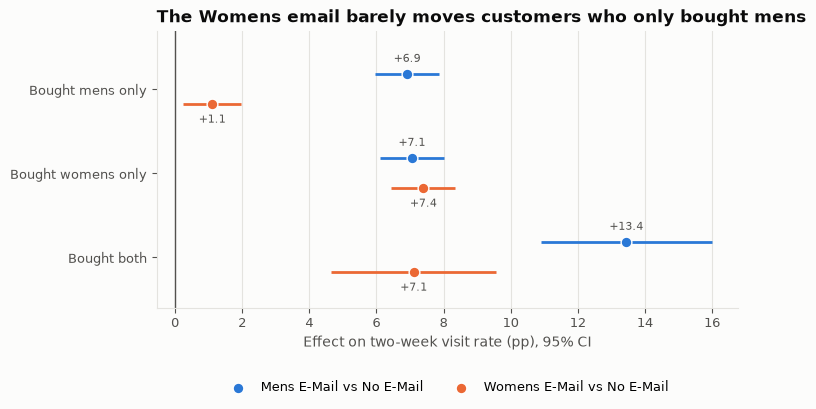

In [6]:
pg = seg[(seg["dimension"] == "purchase_group") & (seg["metric"] == "visit")]
level_labels = {"mens_only": "Bought mens only", "womens_only": "Bought womens only", "both": "Bought both"}
levels = ["mens_only", "womens_only", "both"]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
y_base = np.arange(len(levels))[::-1]
for offset, email, dy, va in [(0.18, "mens", 7, "bottom"), (-0.18, "womens", -7, "top")]:
    sub = pg[pg["email"] == email].set_index("level").loc[levels]
    y = y_base + offset
    ax.hlines(y, 100 * sub["ci_low"], 100 * sub["ci_high"], color=ARM_COLORS[email], lw=2)
    ax.scatter(100 * sub["estimate"], y, s=60, color=ARM_COLORS[email], edgecolor="white", linewidth=1,
               zorder=3, label=f"{ARM_LABELS[email]} vs No E-Mail")
    for yi, est in zip(y, sub["estimate"]):
        ax.annotate(f"{100 * est:+.1f}", (100 * est, yi), xytext=(0, dy), textcoords="offset points",
                    ha="center", va=va, fontsize=8, color=TEXT_SECONDARY)
ax.axvline(0, color=TEXT_SECONDARY, lw=1)
ax.set_yticks(y_base, [level_labels[level] for level in levels])
ax.set_ylim(-0.6, len(levels) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on two-week visit rate (pp), 95% CI")
ax.set_title("The Womens email barely moves customers who only bought mens", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
save_figure(fig, "06_segment_effects_purchase_group")
plt.show()

### What the segment analysis shows

- **Past purchase category is the one dimension that clearly matters, and only for visits** (Holm-adjusted p < 0.001 for both emails).
  - The **Womens email** raises visits by about 7 pp among customers who bought women's items (alone or with men's), but only about **+1 pp** among customers who bought men's items only.
  - The **Mens email** works about equally well on mens-only and womens-only buyers (+7 pp each) and about twice as well on customers who bought both (+13 pp).
- **Channel:** no evidence that either email works differently for Phone, Web or Multichannel customers.
- **Past-year spend (`history_segment`):** the Mens visit effect drifts upward with past spend, and the Womens spend effect looks uneven across levels, but neither survives the Holm correction. With 12 heterogeneity tests, one raw p-value near 0.04 is what chance alone would produce.
- **Spend:** none of the spend heterogeneity tests survive correction. Spend effects within segments have intervals several times wider than their estimates, so the data cannot say whether spend responses differ between segments.

**Implication for targeting:** the clearest rule from these pre-specified segments is *don't send the Womens email to customers who only buy men's items*. Whether a model using all features together can find more than this is the question of the next section.

**What we cannot claim:** these are associations between pre-treatment characteristics and the size of the effect. They say *who* responds more, not *why*: for example, mens-only buyers may ignore the Womens email because of its content, or because of something else correlated with buying only men's items.